# STimage read-out vs our negative binomial (paper version)

Draws the comparison behind the STimage sentence of the results section, with the same cascade down to the donor and the same two provenance gates as the rest of canal 2.

**The two arms, and where they come from.** `sti_v1` supplies the STimage heads, `de_6` supplies ours — NOT `pr_classic3`, which is what the rest of the paper's figures use. Both are read in ENSEMBLE mode, so the leaf is `<model_dir>/ensemble/canal2_uncertainty/<source>/` with no `lambda_` level.

| axis | STimage | ours | reported on |
|---|---|---|---|
| **cp** | `STI_nb_cp` | `negativebinomial_hetero_noanchor_cp` | log1p(CP10k) |
| **raw** | `STI_nb_raw` | `negativebinomial_hetero_noanchor_raw` | log1p(raw counts) |

**The figure draws all four arms.** Mixing a cp and a raw head in one panel is licit here and only here: the plotted quantity is a rank correlation, invariant under any monotone transformation of the error, hence comparable across reporting axes. A LEVEL would not be, and none appears. The residual caveat is that the populations differ slightly, the raw target detecting entries that `round(CP_T)` sends to zero.

**Source = `aleatoric`, deliberately.** That is the head's own predictive claim, `var = mu + alpha*mu^2`, which is exactly what the architecture changes. The epistemic term is across-seed disagreement and therefore answers to the training recipe, which also differs between the arms — the most confounded of the three. All three are computed; only `aleatoric` is drawn.

**What is NOT isolated.** STimage differs from us in architecture AND in training recipe (lr, epochs, patience, selection criterion), because `ensemble.classic.hyperparams` is global to a run. So a gap here mixes the two. The only pure architecture A/B would be `STI_nb_cp` trained with the `de_6` recipe.

Paper conventions: left measured legend, one shared x label, compact rows, and the printed twin built from the drawn data.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)
from src.evaluation.benchmark_summary import donor_lopo_stats

RESULTS    = PROJ / 'results'
DATASETS   = ['10x_TuPro', 'TLS', 'LUNG_CANCER']
RADIUS     = 'r75'
N_PLUS_MIN = 60      # canal2's own inclusion filter, RE-APPLIED here: the parquets hold EVERY
                     # present group, so filtering is the reader's job
FIGDIR     = PROJ / 'results' / '_analysis' / 'figures_paper'

# -- THE TWO COLUMN CONVENTIONS -----------------------------------------------------------------
# Two schemas exist in the tree. The CURRENT one writes r_uD_{case} / r_partial_{case} for case
# in lin_all / lin_pos / log_pos, with n_plus_all and n_plus_pos. The other writes
# r_uD_linear / r_partial_linear (absolute error, detected entries) and r_uD / r_partial
# (log ratio), with a single n_plus.
#
# The column names are PROBED, never guessed: a wrong name raises nothing, it makes every
# value NaN and the whole figure mute, which is why the names are probed rather than
# assumed.
SCHEMAS = {
    'v2': {   # the three cases, lin_all included
        'lin_all': dict(naive='r_uD_lin_all', ctrl='r_partial_lin_all',
                        label='absolute error, all entries', n='n_plus_all'),
        'lin_pos': dict(naive='r_uD_lin_pos', ctrl='r_partial_lin_pos',
                        label='absolute error, detected entries', n='n_plus_pos'),
        'log_pos': dict(naive='r_uD_log_pos', ctrl='r_partial_log_pos',
                        label='relative error, detected entries', n='n_plus_pos'),
    },
    'v1': {   # one population only, y > 0
        'lin_pos': dict(naive='r_uD_linear', ctrl='r_partial_linear',
                        label='absolute error, detected entries', n='n_plus'),
        'log_pos': dict(naive='r_uD', ctrl='r_partial',
                        label='relative error, detected entries', n='n_plus'),
    },
}
# The WANTED case, in order of preference. lin_all first: it is the population of fig:axes,
# fig:sources and fig:knn in the paper, hence the only one that makes this comparison readable
# beside them. lin_pos is the fallback if only the v1 schema is on disk.
WANTED = ['lin_all', 'lin_pos']

SOURCES     = ['aleatoric', 'total', 'epistemic']
MAIN_SOURCE = 'aleatoric'     # the head's own predictive claim -- see the title cell

# -- THE ARMS ----------------------------------------------------------------------------------
# 'axis' is the load-bearing field: it partitions the arms into the two reporting axes, and nothing
# below ever mixes two axes.
ARMS = [
    dict(key='sti_cp',  label='STimage head',      family='STI', axis='cp',
         run_label='sti_v1', run_id='sti_v1', model_type='STI_nb_cp'),
    dict(key='nb_cp',   label='Negative binomial', family='NB',  axis='cp',
         run_label='de_6',   run_id='de_6',   model_type='negativebinomial_hetero_noanchor_cp'),
    dict(key='sti_raw', label='STimage head, raw counts',      family='STI', axis='raw',
         run_label='sti_v1', run_id='sti_v1', model_type='STI_nb_raw'),
    dict(key='nb_raw',  label='Negative binomial, raw counts', family='NB',  axis='raw',
         run_label='de_6',   run_id='de_6',   model_type='negativebinomial_hetero_noanchor_raw'),
]
ARM = {a['key']: a for a in ARMS}
AXIS_PAIRS = [('cp',  'sti_cp',  'nb_cp',  'log1p(CP10k)'),
              ('raw', 'sti_raw', 'nb_raw', 'log1p(raw counts)')]
PLOT_AXIS  = 'cp'     # the ONLY axis the figure draws; raw stays in the printed table

# The NB family keeps its canonical purple; the
# STimage heads take the tab10 slots no model_type currently owns.
ARM_COLORS = {'sti_cp': '#7f7f7f', 'sti_raw': '#bcbd22',
              'nb_cp': '#9467bd', 'nb_raw': '#c5b0d5'}
DATASET_LABELS = {'10x_TuPro': 'Tumor Profiler', 'TLS': 'Kidney/Lung with TLS',
                  'LUNG_CANCER': 'NSCLC'}
GROUPING_TXT = {'gene': 'across the spots of one gene',
                'spot': 'across the genes of one spot'}

# -- slide -> donor ------------------------------------------------------------------------------
# SPLIT unit = donor, METRIC unit = slide (src/data/splitting.py), so canal2's per-slide
# groups are folded up to donors before any interval is taken.
DONOR_MAP = yaml.safe_load((PROJ / 'snake' / 'config' / 'donor_slide_map.yaml').read_text())

def slide_to_donor(ds):
    m = DONOR_MAP.get(ds) or {}
    return {sl: d for d, slides in m.items() for sl in slides}


# -- discovery -----------------------------------------------------------------------------------
def model_dir(arm, ds):
    return (RESULTS / ds / arm['run_id']
            / ('_' + ds + '_hvg_top3000') / RADIUS / arm['model_type'])

def canal2_dir(arm, ds, source):
    return model_dir(arm, ds) / 'ensemble' / 'canal2_uncertainty' / source


RUNS, rows, absent = [], [], []
for a in ARMS:
    for ds in DATASETS:
        for src in SOURCES:
            d = canal2_dir(a, ds, src)
            if not (d / 'summary.json').is_file():
                absent.append((a['key'], ds, src))
                continue
            s = json.loads((d / 'summary.json').read_text())
            RUNS.append(dict(arm=a['key'], dataset=ds, source=src, dir=d, summary=s))
            rows.append({**s, 'arm': a['key'], 'dataset': ds, 'source': src})
SUMMARY = pd.DataFrame(rows)
if SUMMARY.empty:
    raise SystemExit('no canal2 artifact found at all -- check RESULTS and the four arms')
DIRS = {(r['arm'], r['dataset'], r['source']): r['dir'] for r in RUNS}

print('=' * 112)
print('COVERAGE: sources found per (arm, cohort).  3 = complete.')
print('=' * 112)
print((SUMMARY.groupby(['arm', 'dataset'])['source'].nunique().unstack(fill_value=0)
       .reindex(index=[a['key'] for a in ARMS], fill_value=0)
       .reindex(columns=DATASETS, fill_value=0)).to_string())
if absent:
    print()
    print('(!)', len(absent), 'triplets (arm, cohort, source) with no summary.json:')
    for k in absent[:15]:
        print('     ', k)

# -- gate 1: the error floor policy ---------------------------------------------------------------
# Its absence signals the clamp rule that crushed every 0 < mu < floor and manufactured
# exactly-zero errors on the count heads. Two arms on two policies would put
# the paired gap on two error definitions.
if 'error_floor_policy' not in SUMMARY.columns:
    SUMMARY['error_floor_policy'] = None
stale = SUMMARY[SUMMARY['error_floor_policy'] != 'v2_substitute_where_undefined']
if len(stale):
    print()
    print('(!)', len(stale), 'artifacts WITHOUT error_floor_policy=v2_substitute_where_undefined:')
    for _, r in stale.iterrows():
        print('     ', str(r['arm']).ljust(9), str(r['dataset']).ljust(12), r['source'])
    print('    -> re-run canal 2 on them before quoting anything from them.')

# -- gate 2: WHICH column convention is on disk? --------------------------------------------------
# One arm on one convention and the other on the second would pair two error definitions
# together, so a MIXED schema is a hard error and not a warning.
def columns_of(r):
    pp = r['dir'] / 'pair_partial.parquet'
    return set(pd.read_parquet(pp).columns) if pp.is_file() else set()

seen = {}
for r in RUNS:
    cols = columns_of(r)
    if not cols:
        continue
    hit = next((name for name, spec in SCHEMAS.items()
                if all(c['ctrl'] in cols for c in spec.values())), None)
    seen.setdefault(hit, []).append((r['arm'], r['dataset'], r['source']))

print()
print('COLUMN SCHEMA found on disk:')
for name, who in seen.items():
    print('  ', str(name).ljust(6), len(who), 'artifact(s)')
if len(seen) != 1 or None in seen:
    print()
    print('(!) schema missing or MIXED. Columns of the first readable artifact:')
    print('   ', sorted(columns_of(RUNS[0])))
    raise SystemExit('both arms must carry the SAME column convention')

SCHEMA = next(iter(seen))
ERRORS = SCHEMAS[SCHEMA]
MAIN   = next(c for c in WANTED if c in ERRORS)
OTHER  = next((c for c in ERRORS if c != MAIN), MAIN)
N_COL  = ERRORS[MAIN]['n']
print()
print('schema           :', SCHEMA)
print('reported case   :', MAIN, '--', ERRORS[MAIN]['label'])
print('  columns read   :', ERRORS[MAIN]['naive'], '(naive),', ERRORS[MAIN]['ctrl'], '(controlled)')
print('robustness       :', OTHER, '--', ERRORS[OTHER]['label'])
print('group size:', N_COL)
if MAIN != 'lin_all':
    print()
    print("(!) lin_all is not available on this schema: the comparison will use the detected")
    print('    DETECTED, hence on a population different from fig:axes / fig:sources / fig:knn.')

COVERAGE: sources found per (arm, cohort).  3 = complete.
dataset  10x_TuPro  TLS  LUNG_CANCER
arm                                 
sti_cp           3    3            3
nb_cp            3    3            3
sti_raw          3    3            3
nb_raw           3    3            3

COLUMN SCHEMA found on disk:
   v2     36 artifact(s)

schema           : v2
reported case   : lin_all -- absolute error, all entries
  columns read   : r_uD_lin_all (naive), r_partial_lin_all (controlled)
robustness       : lin_pos -- absolute error, detected entries
group size: n_plus_all


## 1. The donor cascade, and the paired gap

Per-pair values are folded to `(gene, donor)` weighted by the group size, then averaged over the donor's genes on the gene axis; on the spot axis a spot belongs to one slide hence one donor and the mean is direct.

The gap is **STI minus NB, donor by donor**, so it is the statistic of the differences and not the difference of the statistics. Pairing cancels the donor effect, which dominates the raw spread.

In [2]:
PAIR_COLS = ['gene', 'slide', N_COL] + [ERRORS[e][c] for e in ERRORS for c in ('naive', 'ctrl')]
SPOT_COLS = ['slide', 'spot', N_COL] + [ERRORS[e][c] for e in ERRORS for c in ('naive', 'ctrl')]


def load_groups(arm_key, ds, source, kind):
    """pair_partial (gene axis) or spot_partial (spot axis), filtered at canal2's own floor."""
    d = DIRS.get((arm_key, ds, source))
    fname, cols = (('pair_partial.parquet', PAIR_COLS) if kind == 'gene'
                   else ('spot_partial.parquet', SPOT_COLS))
    if d is None or not (d / fname).is_file():
        return None
    have = set(pd.read_parquet(d / fname).columns)
    g = pd.read_parquet(d / fname, columns=[c for c in cols if c in have])
    for c in cols:
        if c not in g.columns:
            g[c] = np.nan
    return g[g[N_COL] >= N_PLUS_MIN].copy()


GPAIR = {(k, ds, src): g for k in ARM for ds in DATASETS for src in SOURCES
         if (g := load_groups(k, ds, src, 'gene')) is not None}
GSPOT = {(k, ds, src): g for k in ARM for ds in DATASETS for src in SOURCES
         if (g := load_groups(k, ds, src, 'spot')) is not None}
print(len(GPAIR), 'gene-axis tables,', len(GSPOT), 'spot-axis tables')


def gene_donor_matrix_canal2(pp, ds, col):
    """(gene x donor) for one per-pair column. Same n+ weighting as the script."""
    d = pp[pp[col].notna()].copy()
    if d.empty:
        return pd.DataFrame()
    s2d = slide_to_donor(ds)
    d['donor'] = d['slide'].map(lambda s: s2d.get(s, s))
    d['w'] = d[col] * d[N_COL]
    g = d.groupby(['gene', 'donor']).agg(sw=('w', 'sum'), sn=(N_COL, 'sum')).reset_index()
    g['val'] = g['sw'] / g['sn']
    return g.pivot(index='gene', columns='donor', values='val')


def donor_points(arm_key, ds, source, grouping, col):
    """{donor: value} -- the K per-donor points, BEFORE any interval. None if silent."""
    if grouping == 'gene':
        pp = GPAIR.get((arm_key, ds, source))
        if pp is None:
            return None
        mat = gene_donor_matrix_canal2(pp, ds, col)
        if mat.empty:
            return None
        return {k: v for k, v in mat.mean(axis=0, skipna=True).to_dict().items() if np.isfinite(v)}
    sp = GSPOT.get((arm_key, ds, source))
    if sp is None:
        return None
    d = sp[sp[col].notna()]
    if d.empty:
        return None
    s2d = slide_to_donor(ds)
    return d.groupby(d['slide'].map(lambda s: s2d.get(s, s)))[col].mean().to_dict()


def stat_of(points):
    if not points:
        return None
    st = donor_lopo_stats(points)
    if not np.isfinite(st['mean']):
        return None
    return dict(mean=st['mean'], lo=st['ci95_mean'][0], hi=st['ci95_mean'][1], K=st['K'])


def paired_delta(k_sti, k_nb, ds, source, grouping, col):
    """STI minus NB, donor by donor. The stat of the DELTAS, not the delta of the stats."""
    a = donor_points(k_sti, ds, source, grouping, col)
    b = donor_points(k_nb, ds, source, grouping, col)
    if not a or not b:
        return None
    common = sorted(set(a) & set(b))
    if not common:
        return None
    return stat_of({d: a[d] - b[d] for d in common})


ROWS = []
for axis, sti_key, nb_key, ax_txt in AXIS_PAIRS:
    for ds in DATASETS:
        for src in SOURCES:
            for grp in ('gene', 'spot'):
                for err in ERRORS:
                    for cond in ('naive', 'ctrl'):
                        col = ERRORS[err][cond]
                        ROWS.append(dict(
                            axis=axis, dataset=ds, source=src, grouping=grp, error=err, cond=cond,
                            sti=stat_of(donor_points(sti_key, ds, src, grp, col)),
                            nb=stat_of(donor_points(nb_key, ds, src, grp, col)),
                            delta=paired_delta(sti_key, nb_key, ds, src, grp, col)))
TAB = pd.DataFrame(ROWS)
print(len(TAB), 'rows (axis x cohort x source x grouping x error x condition)')

36 gene-axis tables, 36 spot-axis tables
216 rows (axis x cohort x source x grouping x error x condition)


## 2. The paper figure — four arms, both groupings

Same conventions as `fig:axes`: hollow marker = no control, filled marker = the partial correlation controlling for the predicted mean, bar = Student-$t$ 95% interval over held-out donors, drawn on the controlled value only.

Rows: *a)* across the spots of one gene, *b)* across the genes of one spot.

The `raw` pair is drawn below the cp pair, separated by a light rule. This is legitimate because the plotted quantity is a rank correlation and therefore invariant to the reporting axis; levels are never shown.

legend strip = 0.211 of the width
wrote -> fig_sti_vs_nb_paper_aleatoric.pdf


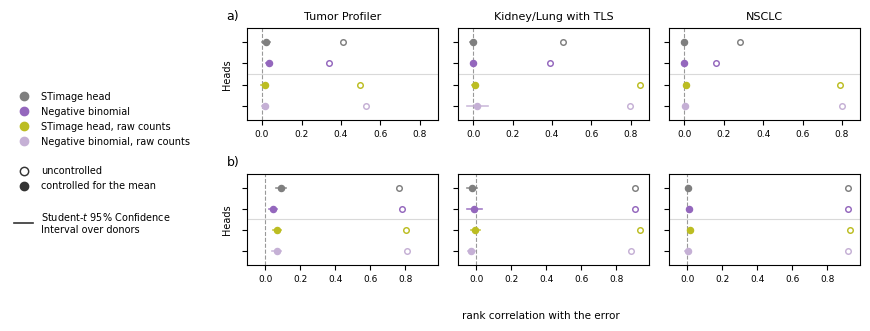


PRINTED TWIN - source aleatoric | absolute error, all entries
  RANK Spearman: comparable between the cp axis and the raw axis. LEVELS would not be.

[across the spots of one gene]
  cohort                head                              axis     naivecontrolled                95% CI
  Tumor Profiler        STimage head                      cp     +0.4087   +0.0190    [-0.0025, +0.0405]
  Tumor Profiler        Negative binomial                 cp     +0.3405   +0.0342    [+0.0181, +0.0502]
  Tumor Profiler        STimage head, raw counts          raw    +0.4953   +0.0137    [-0.0045, +0.0319]
  Tumor Profiler        Negative binomial, raw counts     raw    +0.5268   +0.0150    [-0.0003, +0.0303]
  Kidney/Lung with TLS  STimage head                      cp     +0.4555   -0.0004    [-0.0136, +0.0127]
  Kidney/Lung with TLS  Negative binomial                 cp     +0.3896   -0.0022    [-0.0101, +0.0057]
  Kidney/Lung with TLS  STimage head, raw counts          raw    +0.8479   +0.0072 

In [3]:
from matplotlib.lines import Line2D

FIGDIR.mkdir(parents=True, exist_ok=True)
STEM = 'fig_sti_vs_nb_paper_' + MAIN_SOURCE

GROUPINGS = ['gene', 'spot']          # a) then b), same order as fig:axes
# THE FOUR ARMS, the cp pair then the raw pair. Placing a cp arm and a raw arm in the SAME
# panel is licit HERE and only here: the plotted quantity is a RANK correlation, invariant
# (Spearman), invariant under any monotone transformation of the error, hence comparable from one
# from one reporting axis to the other. A LEVEL (mean error, sparsification start) is not, and
# appears nowhere in this figure.
# One caveat remains: the populations differ slightly, the raw target detecting entries
# that round(CP_T) sends to zero.
PLOT_ARMS = ['sti_cp', 'nb_cp', 'sti_raw', 'nb_raw']

COL_W         = 2.9    # width is the cheap axis: LaTeX places the figure at a fixed width
ROW_H         = 1.7    # four arms per panel instead of two
LEGEND_FS     = 7
LEGEND_GUTTER = 0.02
BOTTOM_PAD    = 0.10   # strip reserved for the SHARED axis label

drawn = []
fig, axes = plt.subplots(len(GROUPINGS), len(DATASETS),
                         figsize=(COL_W * len(DATASETS), ROW_H * len(GROUPINGS)),
                         sharex='row', squeeze=False)
for i, grp in enumerate(GROUPINGS):
    for j, ds in enumerate(DATASETS):
        ax = axes[i, j]
        for y, k in enumerate(PLOT_ARMS):
            # each arm is read on ITS OWN reporting axis, never on a hardcoded one
            sub = TAB[(TAB['axis'] == ARM[k]['axis']) & (TAB['dataset'] == ds)
                      & (TAB['source'] == MAIN_SOURCE) & (TAB['grouping'] == grp)
                      & (TAB['error'] == MAIN)]
            side = 'sti' if ARM[k]['family'] == 'STI' else 'nb'
            nv = sub[sub['cond'] == 'naive'][side]
            cv = sub[sub['cond'] == 'ctrl'][side]
            nv = nv.iloc[0] if len(nv) else None
            cv = cv.iloc[0] if len(cv) else None
            c = ARM_COLORS[k]
            if nv is not None:
                ax.plot([nv['mean']], [y], 'o', ms=4.0, mfc='none', mec=c, mew=1.05, zorder=3)
            if cv is not None:
                ax.plot([cv['lo'], cv['hi']], [y, y], color=c, lw=1.2, alpha=0.85, zorder=3)
                ax.plot([cv['mean']], [y], 'o', ms=4.4, color=c, zorder=4)
            drawn.append(dict(grouping=grp, cohort=DATASET_LABELS.get(ds, ds), arm=k,
                              head=ARM[k]['label'], reported_on=ARM[k]['axis'],
                              naive=(nv['mean'] if nv is not None else np.nan),
                              ctrl=(cv['mean'] if cv is not None else np.nan),
                              lo=(cv['lo'] if cv is not None else np.nan),
                              hi=(cv['hi'] if cv is not None else np.nan)))
        # separator between the cp pair (top) and the raw pair (bottom): two reporting axes
        ax.axhline(1.5, color='0.85', lw=0.8, zorder=0)
        ax.axvline(0.0, color='0.6', lw=0.8, ls='--', zorder=1)
        ax.set_yticks(range(len(PLOT_ARMS)))
        ax.set_yticklabels([])          # the COLOR identifies the arm, see the left legend
        ax.invert_yaxis()
        ax.margins(y=0.22)
        ax.tick_params(axis='x', labelsize=6.5)
        if j == 0:
            ax.set_ylabel('Heads', fontsize=7)
            ax.text(-0.04, 1.06, "ab"[i] + ')', transform=ax.transAxes,
                    ha='right', va='bottom', fontsize=9)
        if i == 0:
            ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)
        # NO per-column set_xlabel: three copies of the same text overlap.

head_handles = [Line2D([], [], marker='o', ls='', color=ARM_COLORS[k], label=ARM[k]['label'])
                for k in PLOT_ARMS]
sp1, sp2 = (Line2D([], [], ls='', marker='', label='') for _ in range(2))
cond_handles = [Line2D([], [], marker='o', ls='', mfc='none', mec='#333333', mew=1.05,
                       label='uncontrolled'),
                Line2D([], [], marker='o', ls='', color='#333333',
                       label='controlled for the mean')]
bar_handle = [Line2D([], [], color='#333333', lw=1.2, marker='',
                     label='Student-$t$ 95% Confidence \nInterval over donors')]
leg = fig.legend(handles=head_handles + [sp1] + cond_handles + [sp2] + bar_handle,
                 loc='center left', bbox_to_anchor=(0.0, 0.5),
                 ncol=1, frameon=False, fontsize=LEGEND_FS)
fig.canvas.draw()
legend_w = leg.get_window_extent().width / fig.bbox.width
left = legend_w + LEGEND_GUTTER
fig.tight_layout(rect=(left, BOTTOM_PAD, 1, 1))
fig.text((left + 1) / 2, BOTTOM_PAD / 2, 'rank correlation with the error',
         ha='center', va='center', fontsize=7.5)
print('legend strip =', format(legend_w, '.3f'), 'of the width')

for ext in ('pdf', 'png'):
    fig.savefig(FIGDIR / (STEM + '.' + ext), dpi=300, bbox_inches='tight')
print('wrote ->', (STEM + '.pdf'))
plt.show()


# ======================== THE PRINTED TWIN OF THE FIGURE ======================================
# Exactly the drawn points, the four arms, with the reporting axis in the column. These are
# RANKS, hence comparable from one axis to the other; no LEVEL is printed here.
D = pd.DataFrame(drawn)
print()
print('=' * 112)
print('PRINTED TWIN - source', MAIN_SOURCE, '|', ERRORS[MAIN]['label'])
print('  RANK Spearman: comparable between the cp axis and the raw axis. LEVELS would not be.')
print('=' * 112)
for grp in GROUPINGS:
    print()
    print('[' + GROUPING_TXT[grp] + ']')
    print('  ' + 'cohort'.ljust(22) + 'head'.ljust(34) + 'axis'.ljust(5)
          + 'naive'.rjust(9) + 'controlled'.rjust(10) + '95% CI'.rjust(22))
    for r in D[D['grouping'] == grp].itertuples():
        ci = ('[' + format(r.lo, '+.4f') + ', ' + format(r.hi, '+.4f') + ']'
              if np.isfinite(r.lo) else 'n/a')
        nv = format(r.naive, '+.4f') if np.isfinite(r.naive) else '     n/a'
        cv = format(r.ctrl, '+.4f') if np.isfinite(r.ctrl) else '    mute'
        print('  ' + r.cohort.ljust(22) + r.head.ljust(34) + r.reported_on.ljust(5)
              + nv.rjust(9) + cv.rjust(10) + ci.rjust(22))

# -- the PAIRED gap, the only question this notebook asks ----------------------------------------
# Paired WITHIN an axis only: STI against NB on the same axis, hence on the same population.
print()
print('=' * 112)
print('PAIRED GAP  STI minus NB, donor by donor, WITHIN each reporting axis')
print("  '*' = the paired interval excludes zero. A significant gap is a gap whose")
print('  the PAIRED interval excludes zero, NOT a gap between two significant values.')
print('=' * 112)
print('  ' + 'axis'.ljust(5) + 'cohort'.ljust(22) + 'grouping'.ljust(30)
      + 'naive'.rjust(10) + 'controlled'.rjust(10))
n_sig = n_tot = 0
for axis, sti_key, nb_key, ax_txt in AXIS_PAIRS:
    for ds in DATASETS:
        for grp in GROUPINGS:
            sub = TAB[(TAB['axis'] == axis) & (TAB['dataset'] == ds)
                      & (TAB['source'] == MAIN_SOURCE) & (TAB['grouping'] == grp)
                      & (TAB['error'] == MAIN)]
            cells = []
            for cond in ('naive', 'ctrl'):
                r = sub[sub['cond'] == cond]['delta']
                st = r.iloc[0] if len(r) else None
                if st is None:
                    cells.append('    mute')
                    continue
                hit = st['lo'] > 0 or st['hi'] < 0
                if cond == 'ctrl':
                    n_tot += 1
                    n_sig += int(hit)
                cells.append(format(st['mean'], '+.4f') + ('*' if hit else ' '))
            print('  ' + axis.ljust(5) + DATASET_LABELS.get(ds, ds).ljust(22)
                  + GROUPING_TXT[grp].ljust(30) + cells[0].rjust(10) + cells[1].rjust(10))
print()
print('  CONTROLLED gaps whose paired interval excludes zero:', n_sig, '/', n_tot)